In [1]:
import pandas as pd
import os
import pyarrow.parquet as pq
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torchvision.models import resnet18
from torchvision import transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv("metadata/train.csv")
val_df = pd.read_csv("metadata/val.csv")
test_df = pd.read_csv("metadata/test.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

display(train_df.head())

Train: (90256, 4)
Validation: (10923, 4)
Test: (10941, 4)


,shard,row_index,patient_id,pneumonia
0,train-00000-of-00006.parquet,0,1,0
1,train-00000-of-00006.parquet,1,1,0
2,train-00000-of-00006.parquet,2,1,0
3,train-00000-of-00006.parquet,3,2,0
4,train-00000-of-00006.parquet,4,3,0


In [2]:
device

device(type='cuda')

In [2]:
train_patients = train_df["patient_id"]
val_patients = val_df["patient_id"]
test_patients = test_df["patient_id"]

print("Train-validation overlap:", len(set(train_patients) & set(val_patients)))
print("Train-test overlap:", len(set(val_patients) & set(test_patients)))
print("Validation-test overlap:", len(set(train_patients) & set(test_patients)))

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [3]:
from torch.utils.data import Dataset

class ChestXrayDataset(Dataset):
    def __init__(self, dataframe, data_dir, transform=None, image_mode="RGB"):
        self.dataframe = dataframe.reset_index(drop=True)
        self.data_dir = data_dir
        self.transform = transform
        self.image_mode = image_mode
        # Cache the currently open shard and row group
        self._cached_shard = None
        self._cached_pf = None
        self._cached_row_group = None
        self._cached_table = None
        self._cached_group_start = None
    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        metadata = self.dataframe.iloc[idx]
        shard = metadata["shard"]
        # Open a shard only when it changes
        if shard != self._cached_shard:
            parquet_path = os.path.join(self.data_dir, shard)
            self._cached_pf = pq.ParquetFile(parquet_path)
            self._cached_shard = shard
            self._cached_row_group = None
        pf = self._cached_pf

        row_index = int(metadata["row_index"])
        group_start = 0
        # Find the row group containing this row       
        for g in range(pf.num_row_groups):
            group_rows = pf.metadata.row_group(g).num_rows
        
            if row_index < group_start + group_rows:
                row_group = g
                offset = row_index - group_start
                break
        
            group_start += group_rows
        else:
            raise IndexError(f"Row index {row_index} is out of range")
        # Read a row group only if it isn't already cached
        if row_group != self._cached_row_group:
            self._cached_table = pf.read_row_group(
                row_group, columns=["image", "labels"]
            )
            self._cached_row_group = row_group
            self._cached_group_start = group_start
        
        image_data = self._cached_table.slice(offset, 1)["image"][0].as_py()
        labels = self._cached_table.slice(offset, 1)["labels"][0].as_py()
        
        image = Image.open(
            BytesIO(image_data["bytes"])
        ).convert(self.image_mode)
        target = torch.zeros(14, dtype=torch.float32)

        for label_id in labels:
            if label_id != 0:
                target[label_id - 1] = 1.0
        
        if self.transform:
            image = self.transform(image)
        return image, target

## Adding noise to image

In [11]:
class PoissonNoise:
    def __init__(self, peak=1000):
        if peak <= 0:
            raise ValueError("peak must be positive")
        self.peak = peak

    def __call__(self, image):
        noisy_counts = torch.poisson(image * self.peak)
        noisy_image = noisy_counts / self.peak

        return torch.clamp(noisy_image, 0, 1)
        
normalize = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

poisson_transform = transforms.Compose([
    transforms.ToTensor(),
    PoissonNoise(peak=25),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    normalize,
])

In [5]:
from src.evaluate import load_checkpoint, evaluate_model

pathology_names = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural Thickening", "Hernia"
]

In [6]:

model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 14)
model = load_checkpoint(
    model,
    "checkpoints/resnet18_adam_epoch_3.pth",
    device
)

Loaded epoch: 3


In [24]:
#Sanity check

clean_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    normalize,
])

clean_dataset = ChestXrayDataset(
    val_df,
    data_dir='data/data/',
    transform=clean_transform,
    image_mode="L"
)

val_loader = DataLoader(
    clean_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=6,
)

df, macro_auc = evaluate_model(
    model,
    val_loader,
    device,
    pathology_names
)

display(df)

Loaded epoch: 3
Processed 100/1366 batches
Processed 200/1366 batches
Processed 300/1366 batches
Processed 400/1366 batches
Processed 500/1366 batches
Processed 600/1366 batches
Processed 700/1366 batches
Processed 800/1366 batches
Processed 900/1366 batches
Processed 1000/1366 batches
Processed 1100/1366 batches
Processed 1200/1366 batches
Processed 1300/1366 batches
Macro ROC-AUC: 0.8199


,Name,ROC AUC
0,Atelectasis,0.819626
1,Cardiomegaly,0.914616
2,Effusion,0.871744
3,Infiltration,0.716445
4,Mass,0.852727
5,Nodule,0.702776
6,Pneumonia,0.746072
7,Pneumothorax,0.860455
8,Consolidation,0.793781
9,Edema,0.915597


In [10]:

poisson_dataset = ChestXrayDataset(
    val_df,
    data_dir='data/data/',
    transform=poisson_transform,
    image_mode="L"
)

poisson_loader = DataLoader(
    poisson_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)
poisson_df, poisson_auc = evaluate_model(
    model,
    poisson_loader,
    device,
    pathology_names
)

print(f"Clean AUC:   {0.8199:.4f}")
print(f"Poisson AUC: {poisson_auc:.4f}")
print(f"AUC drop:    {0.8199 - poisson_auc:.4f}")

Processed 10/342 batches
Processed 20/342 batches
Processed 30/342 batches
Processed 40/342 batches
Processed 50/342 batches
Processed 60/342 batches
Processed 70/342 batches
Processed 80/342 batches
Processed 90/342 batches
Processed 100/342 batches
Processed 110/342 batches
Processed 120/342 batches
Processed 130/342 batches
Processed 140/342 batches
Processed 150/342 batches
Processed 160/342 batches
Processed 170/342 batches
Processed 180/342 batches
Processed 190/342 batches
Processed 200/342 batches
Processed 210/342 batches
Processed 220/342 batches
Processed 230/342 batches
Processed 240/342 batches
Processed 250/342 batches
Processed 260/342 batches
Processed 270/342 batches
Processed 280/342 batches
Processed 290/342 batches
Processed 300/342 batches
Processed 310/342 batches
Processed 320/342 batches
Processed 330/342 batches
Processed 340/342 batches
Macro ROC-AUC: 0.5335
Clean AUC:   0.8199
Poisson AUC: 0.5335
AUC drop:    0.2864


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

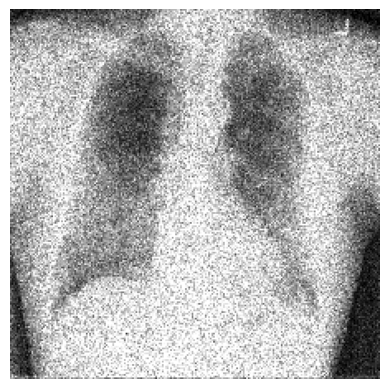

In [13]:
image, label = poisson_dataset[0]

# Reverse ImageNet normalization
mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

image = (image * std + mean).clamp(0, 1)

plt.imshow(image[0], cmap="gray", vmin=0, vmax=1)
plt.axis("off")

In [14]:
poisson_transform = transforms.Compose([
    transforms.ToTensor(),
    PoissonNoise(peak=250),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    normalize,
])

poisson_dataset = ChestXrayDataset(
    val_df,
    data_dir='data/data/',
    transform=poisson_transform,
    image_mode="L"
)

poisson_loader = DataLoader(
    poisson_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)
poisson_df, poisson_auc = evaluate_model(
    model,
    poisson_loader,
    device,
    pathology_names
)

print(f"Clean AUC:   {0.8199:.4f}")
print(f"Poisson AUC: {poisson_auc:.4f}")
print(f"AUC drop:    {0.8199 - poisson_auc:.4f}")

Processed 10/342 batches
Processed 20/342 batches
Processed 30/342 batches
Processed 40/342 batches
Processed 50/342 batches
Processed 60/342 batches
Processed 70/342 batches
Processed 80/342 batches
Processed 90/342 batches
Processed 100/342 batches
Processed 110/342 batches
Processed 120/342 batches
Processed 130/342 batches
Processed 140/342 batches
Processed 150/342 batches
Processed 160/342 batches
Processed 170/342 batches
Processed 180/342 batches
Processed 190/342 batches
Processed 200/342 batches
Processed 210/342 batches
Processed 220/342 batches
Processed 230/342 batches
Processed 240/342 batches
Processed 250/342 batches
Processed 260/342 batches
Processed 270/342 batches
Processed 280/342 batches
Processed 290/342 batches
Processed 300/342 batches
Processed 310/342 batches
Processed 320/342 batches
Processed 330/342 batches
Processed 340/342 batches
Macro ROC-AUC: 0.6733
Clean AUC:   0.8199
Poisson AUC: 0.6733
AUC drop:    0.1466


In [16]:
poisson_transform = transforms.Compose([
    transforms.ToTensor(),
    PoissonNoise(peak=1000),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    normalize,
])

poisson_dataset = ChestXrayDataset(
    val_df,
    data_dir='data/data/',
    transform=poisson_transform,
    image_mode="L"
)

poisson_loader = DataLoader(
    poisson_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)
poisson_df, poisson_auc = evaluate_model(
    model,
    poisson_loader,
    device,
    pathology_names
)

print(f"Clean AUC:   {0.8199:.4f}")
print(f"Poisson AUC: {poisson_auc:.4f}")
print(f"AUC drop:    {0.8199 - poisson_auc:.4f}")

Processed 10/342 batches
Processed 20/342 batches
Processed 30/342 batches
Processed 40/342 batches
Processed 50/342 batches
Processed 60/342 batches
Processed 70/342 batches
Processed 80/342 batches
Processed 90/342 batches
Processed 100/342 batches
Processed 110/342 batches
Processed 120/342 batches
Processed 130/342 batches
Processed 140/342 batches
Processed 150/342 batches
Processed 160/342 batches
Processed 170/342 batches
Processed 180/342 batches
Processed 190/342 batches
Processed 200/342 batches
Processed 210/342 batches
Processed 220/342 batches
Processed 230/342 batches
Processed 240/342 batches
Processed 250/342 batches
Processed 260/342 batches
Processed 270/342 batches
Processed 280/342 batches
Processed 290/342 batches
Processed 300/342 batches
Processed 310/342 batches
Processed 320/342 batches
Processed 330/342 batches
Processed 340/342 batches
Macro ROC-AUC: 0.7457
Clean AUC:   0.8199
Poisson AUC: 0.7457
AUC drop:    0.0742


In [17]:
#another sanity check
poisson_transform = transforms.Compose([
    transforms.ToTensor(),
    PoissonNoise(peak=10000),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    normalize,
])

poisson_dataset = ChestXrayDataset(
    val_df,
    data_dir='data/data/',
    transform=poisson_transform,
    image_mode="L"
)

poisson_loader = DataLoader(
    poisson_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)
poisson_df, poisson_auc = evaluate_model(
    model,
    poisson_loader,
    device,
    pathology_names
)

print(f"Clean AUC:   {0.8199:.4f}")
print(f"Poisson AUC: {poisson_auc:.4f}")
print(f"AUC drop:    {0.8199 - poisson_auc:.4f}")

Processed 10/342 batches
Processed 20/342 batches
Processed 30/342 batches
Processed 40/342 batches
Processed 50/342 batches
Processed 60/342 batches
Processed 70/342 batches
Processed 80/342 batches
Processed 90/342 batches
Processed 100/342 batches
Processed 110/342 batches
Processed 120/342 batches
Processed 130/342 batches
Processed 140/342 batches
Processed 150/342 batches
Processed 160/342 batches
Processed 170/342 batches
Processed 180/342 batches
Processed 190/342 batches
Processed 200/342 batches
Processed 210/342 batches
Processed 220/342 batches
Processed 230/342 batches
Processed 240/342 batches
Processed 250/342 batches
Processed 260/342 batches
Processed 270/342 batches
Processed 280/342 batches
Processed 290/342 batches
Processed 300/342 batches
Processed 310/342 batches
Processed 320/342 batches
Processed 330/342 batches
Processed 340/342 batches
Macro ROC-AUC: 0.8116
Clean AUC:   0.8199
Poisson AUC: 0.8116
AUC drop:    0.0083


In [18]:
#finding knee(mo)
poisson_transform = transforms.Compose([
    transforms.ToTensor(),
    PoissonNoise(peak=5000),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    normalize,
])

poisson_dataset = ChestXrayDataset(
    val_df,
    data_dir='data/data/',
    transform=poisson_transform,
    image_mode="L"
)

poisson_loader = DataLoader(
    poisson_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)
poisson_df, poisson_auc = evaluate_model(
    model,
    poisson_loader,
    device,
    pathology_names
)

print(f"Clean AUC:   {0.8199:.4f}")
print(f"Poisson AUC: {poisson_auc:.4f}")
print(f"AUC drop:    {0.8199 - poisson_auc:.4f}")

Processed 10/342 batches
Processed 20/342 batches
Processed 30/342 batches
Processed 40/342 batches
Processed 50/342 batches
Processed 60/342 batches
Processed 70/342 batches
Processed 80/342 batches
Processed 90/342 batches
Processed 100/342 batches
Processed 110/342 batches
Processed 120/342 batches
Processed 130/342 batches
Processed 140/342 batches
Processed 150/342 batches
Processed 160/342 batches
Processed 170/342 batches
Processed 180/342 batches
Processed 190/342 batches
Processed 200/342 batches
Processed 210/342 batches
Processed 220/342 batches
Processed 230/342 batches
Processed 240/342 batches
Processed 250/342 batches
Processed 260/342 batches
Processed 270/342 batches
Processed 280/342 batches
Processed 290/342 batches
Processed 300/342 batches
Processed 310/342 batches
Processed 320/342 batches
Processed 330/342 batches
Processed 340/342 batches
Macro ROC-AUC: 0.8025
Clean AUC:   0.8199
Poisson AUC: 0.8025
AUC drop:    0.0174


In [19]:
poisson_transform = transforms.Compose([
    transforms.ToTensor(),
    PoissonNoise(peak=2000),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),
    normalize,
])

poisson_dataset = ChestXrayDataset(
    val_df,
    data_dir='data/data/',
    transform=poisson_transform,
    image_mode="L"
)

poisson_loader = DataLoader(
    poisson_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)
poisson_df, poisson_auc = evaluate_model(
    model,
    poisson_loader,
    device,
    pathology_names
)

print(f"Clean AUC:   {0.8199:.4f}")
print(f"Poisson AUC: {poisson_auc:.4f}")
print(f"AUC drop:    {0.8199 - poisson_auc:.4f}")

Processed 10/342 batches
Processed 20/342 batches
Processed 30/342 batches
Processed 40/342 batches
Processed 50/342 batches
Processed 60/342 batches
Processed 70/342 batches
Processed 80/342 batches
Processed 90/342 batches
Processed 100/342 batches
Processed 110/342 batches
Processed 120/342 batches
Processed 130/342 batches
Processed 140/342 batches
Processed 150/342 batches
Processed 160/342 batches
Processed 170/342 batches
Processed 180/342 batches
Processed 190/342 batches
Processed 200/342 batches
Processed 210/342 batches
Processed 220/342 batches
Processed 230/342 batches
Processed 240/342 batches
Processed 250/342 batches
Processed 260/342 batches
Processed 270/342 batches
Processed 280/342 batches
Processed 290/342 batches
Processed 300/342 batches
Processed 310/342 batches
Processed 320/342 batches
Processed 330/342 batches
Processed 340/342 batches
Macro ROC-AUC: 0.7760
Clean AUC:   0.8199
Poisson AUC: 0.7760
AUC drop:    0.0439
